# California Housing Price Prediction

### From Data Exploration to Model Deployment

**An End-to-End Machine Learning Project**

**Technology Stack:** Python 3.14 · TensorFlow/Keras · Scikit-learn · MLflow · FastAPI · Docker · Streamlit

---

## 1. Project Overview

### Project Aim

The aim of this project is to design, develop, evaluate, and deploy a machine learning system capable of predicting **median housing values in California districts** using geographical, demographic, and housing-related features.

### Business Problem

Median housing values vary considerably across California districts. Factors such as location, household income, housing age, population, and proximity to the ocean may help explain these differences.

Understanding these relationships can support housing market research, regional comparisons, and preliminary planning decisions.

**The central business question is:**

*Can historical housing data and neural networks provide sufficiently useful estimates of district median housing values to support preliminary housing market analysis?*

### Project Objectives

1. Explore the California Housing dataset and identify data quality issues.
2. Prepare numerical and categorical features using a custom preprocessing pipeline.
3. Design and train three neural network architectures.
4. Compare model performance using MAE, RMSE, and R².
5. Track model experiments using MLflow.
6. Package and serve the selected model using FastAPI and Docker.
7. Build an interactive prediction interface using Streamlit.
8. Evaluate the model's practical value, limitations, and potential improvements.

### Expected Business Value

The application provides an accessible tool for estimating district-level median housing values.

It demonstrates how machine learning can support exploratory housing market analysis and how predictions can be made available through an interactive web interface.

### Project Scope and Limitations

The model predicts **district-level median housing values**, not the sale price of an individual property. Predictions should therefore not be treated as professional property valuations.

The modeling dataset also excludes observations with median housing values of **$500,000 or more**. Consequently, the reported model performance does not establish accuracy for those excluded higher-value districts.

---

### Project Workflow

**Data Exploration → Preprocessing → Neural Network Development → Model Evaluation → MLflow Tracking → FastAPI → Docker → Streamlit → Business Conclusions**

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from scipy import sparse
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from califiornia_housing_ml_project.utils.helpers import (
    load_csv_as_dataframe,
    identify_missing_data,
    count_duplicated_rows,
    count_missing_values,
    get_numerical_and_categorical_columns,
)
from califiornia_housing_ml_project.data.preprocessing import AgnosticTabularPreprocessor
from califiornia_housing_ml_project.features.features import housing_math_booster
from califiornia_housing_ml_project.data.data_pipeline import UniversalDataPipeline
from califiornia_housing_ml_project.settings import RANDOM_SEED
from califiornia_housing_ml_project.settings import RANDOM_SEED
from califiornia_housing_ml_project.models.build_model import ModelBuilder, AllowedLoss
from califiornia_housing_ml_project.utils.validator import validate_initial_load


In [5]:
df_raw = load_csv_as_dataframe("housing.csv")
validate_initial_load(df_raw)

df = df_raw.copy()

## 2. Exploratory Data Analysis (EDA)

### Distribution of Median Housing Values

Before developing the prediction models, we examine the distribution of the target variable, `median_house_value`.

This analysis helps us understand the range and distribution of district median housing values, identify possible skewness, and investigate unusual concentrations of observations.

An important characteristic of the California Housing dataset is the concentration of values near its upper recorded limit of approximately **$500,000**.

This suggests that the target variable is affected by an upper-value cap, which has implications for data preparation, model evaluation, and the interpretation of predictions.

The following visualization examines the original target distribution before any filtering is applied.

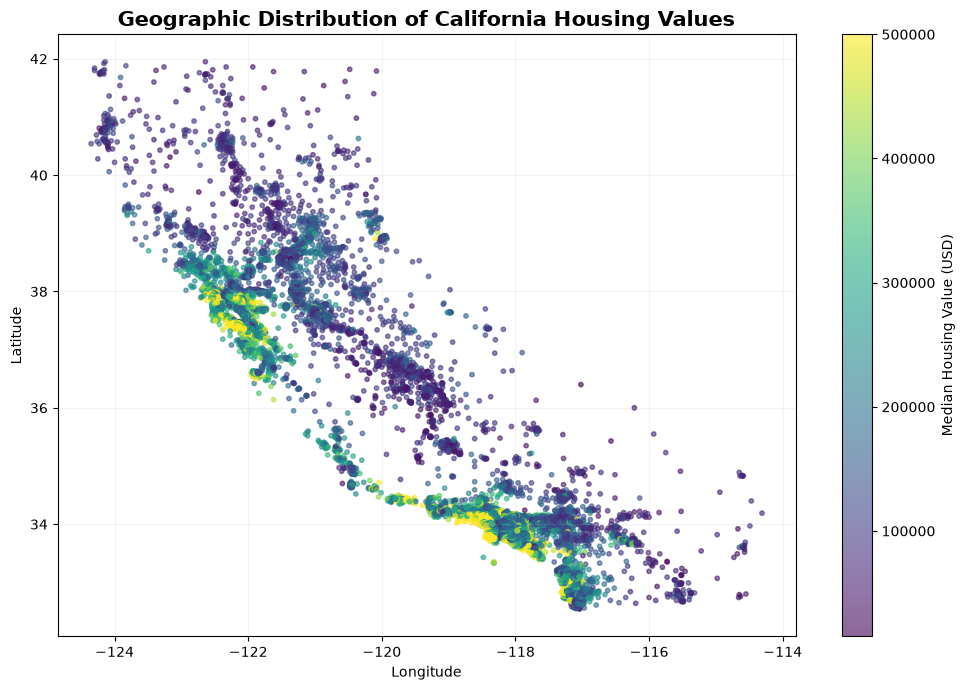

In [6]:

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    df["longitude"],
    df["latitude"],
    c=df["median_house_value"],
    cmap="viridis",
    s=10,
    alpha=0.6,
)

colorbar = fig.colorbar(scatter, ax=ax)
colorbar.set_label("Median Housing Value (USD)")

ax.set_title(
    "Geographic Distribution of California Housing Values",
    fontsize=15,
    fontweight="bold",
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


### Correlation Analysis of Housing Features

Correlation analysis helps us examine the **linear relationships between numerical variables** in the California Housing dataset.

The following heatmap displays **Pearson correlation coefficients**, which range from -1 to +1:

- **Positive correlation:** Higher values of one variable tend to be associated with higher values of another.
- **Negative correlation:** Higher values of one variable tend to be associated with lower values of another.
- **Correlation near zero:** There is little evidence of a linear relationship between the variables.

We are particularly interested in the relationships between the numerical input features and the target variable, `median_house_value`.

**Important considerations:**

- **Correlation does not imply causation.**
- Pearson correlation measures linear relationships, so it may not capture nonlinear patterns.
- A feature with weak linear correlation may still provide useful information to a neural network when combined with other features.

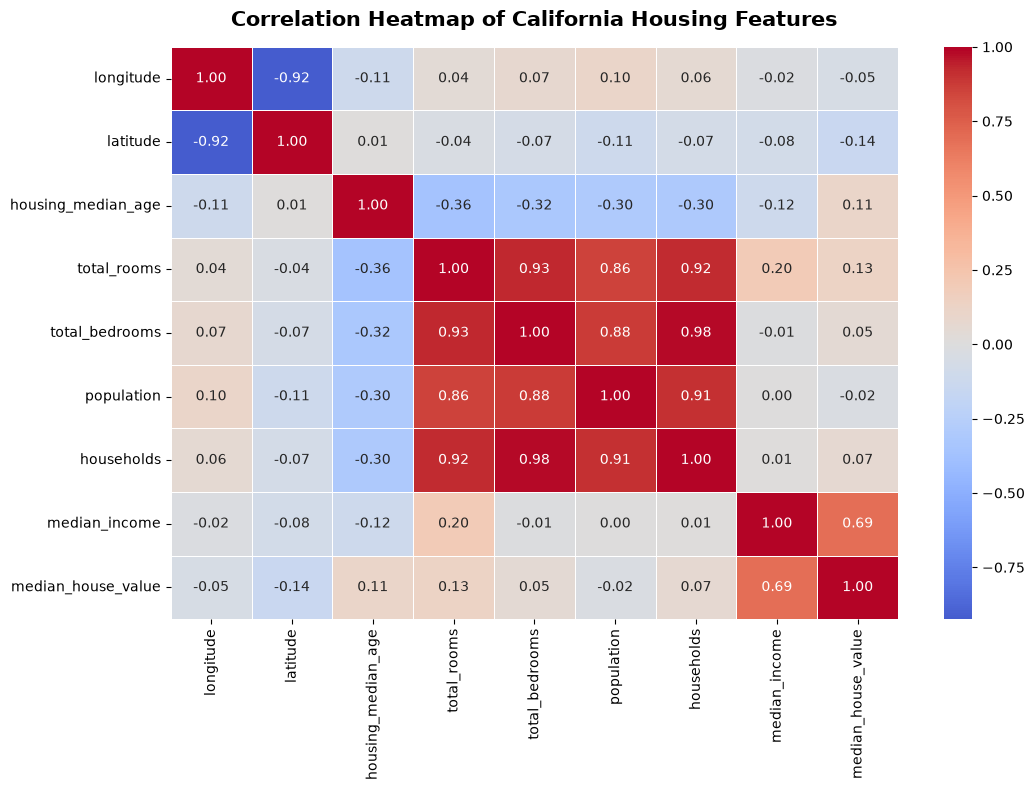

In [7]:

# Select numerical columns only
numeric_df = df.select_dtypes(include="number")

# Calculate correlation matrix
corr_matrix = numeric_df.corr(method="pearson")

# Plot heatmap
fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    ax=ax,
)

ax.set_title(
    "Correlation Heatmap of California Housing Features",
    fontsize=15,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()
plt.show()


### Dataset Structure and Data Quality Inspection

Before preparing the data for modeling, we inspect the California Housing dataset to understand its structure, feature types, and data quality.

The original dataset contains **20,640 observations and 10 columns**, consisting of **nine input features** and one target variable, `median_house_value`.

Our inspection focuses on:

- Dataset dimensions and column names.
- Numerical and categorical data types.
- Descriptive statistics and value ranges.
- Missing values and duplicate records.

These checks help identify potential data-quality issues and determine which preprocessing steps will be required before model development.

In [8]:
df = df.copy()
rows, columns = df.shape

print((rows, columns))


(20640, 10)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [9]:

display(df.head())


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Initial Data Quality Checks

Before preparing the data for model training, we examine the dataset for missing values, unexpected data types, and duplicate records.

We also review descriptive statistics to understand the range, central tendency, and variability of the numerical features.

These checks help us determine which cleaning and preprocessing steps are necessary.

**Target variable:** `median_house_value`, representing the median house value of each California district.

The remaining nine columns serve as the input features for our regression models.

In [7]:
count_duplicated_rows(df)
count_missing_values(df)
identify_missing_data(df)

There are no duplicated rows.
Number of missing values found: 207


(total_bedrooms    207
 dtype: int64,
 ['total_bedrooms'])

## 3. Data Preparation and Preprocessing

### Feature and Target Preparation

The California Housing dataset contains numerical and categorical features describing district-level housing characteristics, demographics, and geographical location.

The target variable is `median_house_value`, which our neural network models are trained to predict.

We separate the target variable from the nine input features so that the models cannot directly access the value they are trying to predict.

Before model development, observations with median housing values of **$500,000 or more** are excluded, leaving **19,648 observations**.

This filtering defines the scope of the modeling dataset and means that our evaluation results do not establish predictive performance for the excluded higher-value districts.

### Training, Validation, and Test Splits

The filtered dataset is initially divided into:

- **80% training pool:** Used for model development, including training and validation.
- **20% held-out test set:** Reserved for final evaluation after selecting the model.

The training pool is subsequently divided into separate training and validation subsets.

| Dataset | Observations | Purpose |
|---|---:|---|
| Training | 12,574 | Fit the neural networks |
| Validation | 3,144 | Compare architectures and select the model |
| Held-out test | 3,930 | Evaluate the selected model |

A fixed random seed helps make these splits reproducible.

To reduce data leakage, preprocessing transformations must be fitted using training data and then applied consistently to validation and test observations without refitting on those datasets.

This approach supports a more reliable comparison of the neural network architectures while keeping the held-out test data separate from model selection.

### Data Preprocessing and Feature Engineering

#### Why Preprocessing Is Necessary

The California Housing dataset contains numerical and categorical features, along with missing values in the `total_bedrooms` column.

Neural networks require numerical inputs, and differences in feature scales can affect the training and optimization process.

To address these requirements, the project uses a reusable preprocessing system built around the custom `UniversalDataPipeline` and `AgnosticTabularPreprocessor` classes.

#### Preprocessing Strategy

The preprocessing workflow includes:

1. **Missing-value handling:** Apply a fitted imputation strategy to numerical features with missing observations.
2. **Categorical encoding:** Convert `ocean_proximity` into a numerical representation.
3. **Feature scaling:** Transform numerical features to support neural network optimization.
4. **Feature transformation:** Produce the numerical input matrix required by TensorFlow/Keras.
5. **Target scaling:** Train the neural networks using transformed target values and convert predictions back into US dollars for evaluation and interpretation.

The nine original input features are transformed into **17 numerical model inputs**.

#### Consistency Across Models

The same preprocessing approach is used for all three neural network architectures.

This ensures that differences in validation performance can be attributed more meaningfully to the model configurations rather than inconsistent feature preparation.

#### Preventing Data Leakage

Preprocessing parameters should be learned from the appropriate training data and reused when transforming validation and test observations.

The held-out test dataset must not be used to fit preprocessing transformations or guide model selection.

We will verify that the custom pipeline follows these rules when reviewing its implementation.

#### Reusing Preprocessing During Deployment

The fitted preprocessing artifacts are saved alongside the selected neural network.

During inference, the FastAPI backend uses these artifacts to transform incoming housing features consistently with the model's expected input representation.

This reduces the risk of differences between notebook predictions and deployed predictions.

### Implementing the Data Split

We use the custom `UniversalDataPipeline` to create reproducible training and held-out test partitions.

The pipeline is initialized with `test_size=0.2` and a fixed random seed.

The following code prepares the input features and target variable, then initializes the pipeline used throughout model development.

In [14]:

numerical_columns_index, categorical_columns_index = (
    get_numerical_and_categorical_columns(
        df,
        numerical_exclude_cols=["median_house_value"],
    )
)

housing_column_transformer = AgnosticTabularPreprocessor(
    numerical_columns=numerical_columns_index.to_list(),
    categorical_columns=categorical_columns_index.to_list(),
    engineering_func=housing_math_booster,
)


### Target Value Filtering and Dataset Preparation

Before splitting the dataset, we exclude observations where `median_house_value >= 500000`.

This removes **992 observations (4.81%)**, reducing the dataset from **20,640 to 19,648 observations**.

The filtering addresses the concentration of target values near the dataset's upper limit, but it also narrows the scope of the model.

**Important limitation:** The model's reported performance should not be assumed to generalize to California districts with median housing values of $500,000 or more.

The following code applies this filter and prepares the features and target for the data pipeline.

In [ ]:

def percentage(count, total):
    return count / total * 100 if total else 0


def prepare_housing_data(df, housing_column_transformer) -> None:

    # Overview

    original_rows = len(df)
    df_cleaned    = df[df["median_house_value"] < 500000].copy()
    rows, _       = df_cleaned.shape

    X = df_cleaned.drop("median_house_value", axis=1)
    y = df_cleaned["median_house_value"]

    pipeline = UniversalDataPipeline(X=X, y=y, test_size=0.2, random_state=RANDOM_SEED)

    pipeline.set_transformer(housing_column_transformer)
    pipeline.run_test_split()
    pipeline.fit_and_transform()

    train_pool_rows = len(pipeline.X_train)
    test_rows       = len(pipeline.X_test)

    X_test_raw   = pipeline.X_test
    y_test_clean = pipeline.y_test

    X_train_raw, X_val_raw, y_train, y_val = pipeline.run_validation_split()
    
    train_rows = len(X_train_raw)
    val_rows = len(X_val_raw)

    validation_prepared_rows = X_val_raw.shape[0]
    validation_answers_rows = y_val.shape[0]

    
    print("\n" + "=" * 45)
    print("CALIFORNIA HOUSING DATA REPORT")
    print("=" * 45)

    print("[1] DATA CLEANING")
    print(f"Original rows : {original_rows:,}")
    print(f"Removed rows  : {original_rows - rows:,}")
    print(f"Cleaned rows  : {rows:,}")
    print(f"Feature count : {X.shape[1]}")


    print("\n[2] TRAIN / TEST SPLIT AND VALIDATION DATA")
    print(f"{'Dataset':<30}{'Rows':>10}{'Percentage':>15}")
    print("-" * 55)

    for name, count in [
        ("Training pool", train_pool_rows),
        ("Testing", test_rows),
        ("Validation prepared (X)", validation_prepared_rows),
        ("Validation answers (y)", validation_answers_rows),
    ]:
        print(
            f"{name:<30}{count:>10,}"
            f"{percentage(count, rows):>14.2f}%"
        )

    print("-" * 55)
    print(
        f"{'Train pool + testing':<30}"
        f"{train_pool_rows + test_rows:>10,}"
        f"{percentage(train_pool_rows + test_rows, rows):>14.2f}%"
    )

    print(
        "\nTrain/test split check:",
        "PASSED"
        if train_pool_rows + test_rows == rows
        else "CHECK REQUIRED"
    )

    print(
        "Validation feature/answer check:",
        "PASSED"
        if validation_prepared_rows == validation_answers_rows
        else "CHECK REQUIRED"
    )

    # Show the training/validation split
    print("\n[3] TRAINING / VALIDATION SPLIT")
    print(f"{'Dataset':<25}{'Rows':>12}{'Percentage':>15}")
    print("-" * 52)

    for name, count in [
        ("Training", train_rows),
        ("Validation", val_rows),
    ]:
        print(
            f"{name:<25}{count:>12,}"
            f"{percentage(count, train_pool_rows):>14.2f}%"
        )

    print("-" * 52)
    print(
        f"{'Total':<25}{train_rows + val_rows:>12,}"
        f"{percentage(train_rows + val_rows, train_pool_rows):>14.2f}%"
    )

    print(
        "\nValidation split check:",
        "PASSED"
        if train_rows + val_rows == train_pool_rows
        else "CHECK REQUIRED"
    )

    
    print("\n[4] FEATURE AND TARGET SHAPES")
    print(f"Training   : X {X_train_raw.shape}, y {y_train.shape}")
    print(f"Validation : X {X_val_raw.shape}, y {y_val.shape}")
    print(f"Testing    : X {X_test_raw.shape}, y {y_test_clean.shape}")

    X_transformed = pipeline.X_train_combined

    if sparse.issparse(X_transformed):
        has_nan = np.isnan(X_transformed.data).any()
    else:
        has_nan = np.isnan(X_transformed).any()

    print("[5] PREPROCESSING CHECKS")
    print(
        "NaN values in training data:",
        "FOUND" if has_nan else "NONE"
    )

    print("\n" + "=" * 55)
    print("       DATA PREPARATION COMPLETE")
    print("=" * 55 + "\n")

    return pipeline

In [15]:

def prepare_housing_data(df, housing_column_transformer):
    """Filter housing data, prepare the splits, and verify their shapes."""

    original_rows = len(df)

    df_filtered = df.loc[
        df["median_house_value"] < 500000
    ].copy()

    X = df_filtered.drop(columns="median_house_value")
    y = df_filtered["median_house_value"]

    pipeline = UniversalDataPipeline(
        X=X,
        y=y,
        test_size=0.2,
        random_state=RANDOM_SEED,
    )

    pipeline.set_transformer(housing_column_transformer)
    pipeline.run_test_split()
    pipeline.fit_and_transform()

    X_train_prepared, X_val_prepared, y_train, y_val = (
        pipeline.run_validation_split()
    )

    X_test_prepared = pipeline.X_test_combined

    train_pool_rows = len(pipeline.X_train)
    test_rows = len(pipeline.X_test)

    # Verify that the partitions contain all filtered observations.
    assert train_pool_rows + test_rows == len(df_filtered)
    assert len(X_train_prepared) + len(X_val_prepared) == train_pool_rows

    # Verify feature and target alignment.
    assert len(X_train_prepared) == len(y_train)
    assert len(X_val_prepared) == len(y_val)
    assert len(X_test_prepared) == len(pipeline.y_test)

    # Verify that all model inputs are finite.
    for name, features in [
        ("Training", X_train_prepared),
        ("Validation", X_val_prepared),
        ("Test", X_test_prepared),
    ]:
        values = features.data if sparse.issparse(features) else features
        assert np.isfinite(values).all(), (
            f"{name} features contain NaN or infinite values."
        )

    print("CALIFORNIA HOUSING DATA PREPARATION")
    print("-" * 45)
    print(f"Original observations : {original_rows:,}")
    print(f"Excluded observations : {original_rows - len(df_filtered):,}")
    print(f"Filtered observations : {len(df_filtered):,}")
    print(f"Raw input features    : {X.shape[1]}")

    print("\nDATA PARTITIONS")
    print(f"Training pool : {train_pool_rows:,}")
    print(f"Training      : {len(X_train_prepared):,}")
    print(f"Validation    : {len(X_val_prepared):,}")
    print(f"Held-out test : {test_rows:,}")

    print("\nPREPARED FEATURE SHAPES")
    print(f"Training   : {X_train_prepared.shape}")
    print(f"Validation : {X_val_prepared.shape}")
    print(f"Held-out test: {X_test_prepared.shape}")

    print("\nData preparation checks: PASSED")

    return pipeline


In [16]:
pipeline = prepare_housing_data(df, housing_column_transformer)

# A backup pipeline to ensure that a fresh re-install can be done if the original pipeline is overwritten
backup_pipeline = pipeline


CALIFORNIA HOUSING DATA PREPARATION
---------------------------------------------
Original observations : 20,640
Excluded observations : 992
Filtered observations : 19,648
Raw input features    : 9

DATA PARTITIONS
Training pool : 15,718
Training      : 12,574
Validation    : 3,144
Held-out test : 3,930

PREPARED FEATURE SHAPES
Training   : (12574, 17)
Validation : (3144, 17)
Held-out test: (3930, 17)

Data preparation checks: PASSED


### Implementing the Model Architectures

We use our custom `ModelBuilder` to construct and compile the three neural networks with consistent training settings.

In [12]:

# Verify the corrected data pipeline

X_train = pipeline.X_train_split
X_val = pipeline.X_val_split
X_test = pipeline.X_test_combined

assert X_train.shape == (12574, 17)
assert X_val.shape == (3144, 17)
assert X_test.shape == (3930, 17)

assert len(pipeline.y_train_split) == len(X_train)
assert len(pipeline.y_val_split) == len(X_val)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

# Confirm the feature scaler was fitted on training rows only
assert pipeline.transformer._scaler.n_samples_seen_ == 12574

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Held-out test:", X_test.shape)
print("Preprocessor fitted on training subset only: PASSED")
print("All pipeline checks: PASSED")


Training: (12574, 17)
Validation: (3144, 17)
Held-out test: (3930, 17)
Preprocessor fitted on training subset only: PASSED
All pipeline checks: PASSED


## 4. Neural Network Model Development

### Model Development Strategy

We develop and compare three artificial neural network (ANN) architectures to predict California district-level median housing values.

The experiment investigates how **network width and depth** influence predictive performance. All models use the same prepared training and validation datasets and a consistent training configuration.

### Neural Network Architectures

| Model | Hidden Layers | Architecture | Purpose |
|---|---:|---|---|
| Model 1 | 2 | 64 → 32 | Baseline network |
| Model 2 | 2 | 128 → 64 | Investigate increased width |
| Model 3 | 3 | 64 → 32 → 16 | Investigate increased depth |

Each model receives **17 preprocessed input features** and produces one prediction of the scaled median housing value.

### Training Configuration

| Parameter | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss function | Mean Absolute Error (MAE) |
| Maximum epochs | 100 |
| Batch size | 32 |
| L2 regularization | 0.0001 |
| Dropout rate | 0.1 |
| Batch normalization | Enabled |

The same training settings are used to support a consistent comparison across architectures.

### Model Evaluation and Selection

We evaluate predictive performance using three regression metrics:

- **MAE:** Average absolute prediction error.
- **RMSE:** Penalizes larger prediction errors more heavily.
- **R²:** Measures the proportion of target variance explained by the model.

MAE and RMSE are reported in **US dollars** after reversing the target scaling. R² is calculated using predictions and actual values on the same scale.

The preferred architecture is selected using **validation performance**. The held-out test dataset is reserved for final evaluation of the selected model.

### Building the Neural Network Models

We implement the three neural network architectures using **TensorFlow/Keras**.

Each model receives the same **17 preprocessed input features**. We use a consistent training configuration to compare their predictive performance.

In [23]:

# Retrieve the prepared training and validation datasets.
X_train_prepared = pipeline.X_train_split
X_val_prepared = pipeline.X_val_split
y_train = pipeline.y_train_split
y_val = pipeline.y_val_split


def build_models(model_stats: list[dict], input_dim: int):
    """Build and compile neural networks from model configurations."""

    built_models = []

    for model_info in model_stats:
        if not isinstance(model_info, dict) or len(model_info) != 1:
            raise ValueError(
                "Each model configuration must contain exactly one model."
            )

        model_name, configuration = next(iter(model_info.items()))
        neurons = configuration["neurons"]

        model = (
            ModelBuilder()
            .create_architecture(
                neurons=neurons,
                input_shape=input_dim,
                add_kernel_regularizer=True,
                kernel_regularizer_value=0.0001,
                use_batch_normalization=True,
                dropout_rate=0.1,
                ensure_positive_output=False,
            )
            .add_optimizers(
                learning_rate=0.001,
                loss=AllowedLoss.MAE,
            )
            .build_and_compile()
        )

        built_models.append(model)

    return built_models


In [24]:

models_to_build = [
    {"model_1": {"neurons": [64]}},
    {"model_2": {"neurons": [128, 64]}},
    {"model_3": {"neurons": [64, 32, 16]}},
]

model_1, model_2, model_3 = build_models(
    models_to_build,
    input_dim=X_train_prepared.shape[1],
)

for name, model in [
    ("Model 1", model_1),
    ("Model 2", model_2),
    ("Model 3", model_3),
]:
    print(f"{name}: {model.input_shape}")


Model 1: (None, 17)
Model 2: (None, 17)
Model 3: (None, 17)


### Model Architecture Inspection

Before training, we inspect the three neural networks using **Keras `model.summary()`**.

The summaries allow us to verify:

- The number and types of layers.
- The output shapes of each layer.
- The total and trainable parameter counts.
- The final output dimension for regression.

Each model receives **17 preprocessed input features** and produces a single continuous prediction of the scaled median housing value.

This inspection confirms that the implemented architectures match our experimental design before training begins.

In [ ]:

print("MODEL 1 — BASELINE ARCHITECTURE")
model_1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,473 (5.75 KB)

 Trainable params: 1,345 (5.25 KB)

 Non-trainable params: 128 (512.00 B)

In [21]:

print("MODEL 2 — BASELINE ARCHITECTURE")
model_2.summary()


MODEL 2 — BASELINE ARCHITECTURE


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,393 (44.50 KB)

 Trainable params: 11,009 (43.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [22]:

print("MODEL 3 — BASELINE ARCHITECTURE")
model_3.summary()


MODEL 3 — BASELINE ARCHITECTURE


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,225 (16.50 KB)

 Trainable params: 4,001 (15.63 KB)

 Non-trainable params: 224 (896.00 B)

### Implementing the Model Architectures

We use our custom `ModelBuilder` to construct and compile the three neural networks with consistent training settings.

### Verifying the Three Model Architectures

We inspect the Keras summaries of all three models to confirm their layer configurations, output shapes, and parameter counts.

This verification ensures that the baseline, wider, and deeper networks have been constructed as intended before training.

Although the models differ in complexity, their relative predictive performance will be determined through validation rather than architecture size alone.

In [13]:
for name, model in [
    ("model_1", model_1),
    ("model_2", model_2),
    ("model_3", model_3),
]:
    print(f"\n{name}")
    model.summary()


model_1


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 2,945 (11.50 KB)

...

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,713 (14.50 KB)

 Trainable params: 3,489 (13.63 KB)

 Non-trainable params: 224 (896.00 B)

### Architecture Verification Results

The Keras summaries confirm that all three networks match their intended architectures and produce a single regression output.

| Model | Hidden Layers | Architecture | Total Parameters |
|---|---:|---|---:|
| Model 1 — Baseline | 1 | 64 | 1,473 |
| Model 2 — Wider | 2 | 128 → 64 | 11,393 |
| Model 3 — Deeper | 3 | 64 → 32 → 16 | 4,225 |

Model 2 has the most parameters, while Model 3 has the greatest depth. This illustrates that **network depth and parameter count are not equivalent**.

The preferred architecture will be determined by validation performance rather than model size alone.

### Training the Neural Network Models

We train the three neural network architectures using the **prepared training dataset**, while monitoring predictive performance on a separate validation dataset.

All models use a consistent training configuration:

- **Maximum epochs:** 100
- **Batch size:** 32
- **Validation:** Monitored during training to assess generalization and detect potential overfitting.

The validation dataset is used for performance monitoring and model comparison, but not for gradient-based weight updates.

The **held-out test dataset remains untouched** during training and model selection. It is reserved for the final evaluation of the selected architecture.

In [25]:

# Shared training configuration
EPOCHS = 100
BATCH_SIZE = 32

# Use the existing prepared training and validation datasets.
X_train_prepared = pipeline.X_train_split
X_val_prepared = pipeline.X_val_split
y_train = pipeline.y_train_split
y_val = pipeline.y_val_split

# Train each architecture using the same data and settings.
models = {
    "Model 1": model_1,
    "Model 2": model_2,
    "Model 3": model_3,
}

histories = {}

for name, model in models.items():
    print(f"\n{'=' * 45}")
    print(f"TRAINING {name.upper()}")
    print(f"{'=' * 45}")

    histories[name] = model.fit(
        X_train_prepared,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val_prepared, y_val),
        verbose=1,
    )

# Preserve the original history variable names for later cells.
history_1 = histories["Model 1"]
history_2 = histories["Model 2"]
history_3 = histories["Model 3"]



TRAINING MODEL 1
Epoch 1/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6036 - mae: 0.6010 - val_loss: 0.4645 - val_mae: 0.4619
Epoch 2/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4873 - mae: 0.4847 - val_loss: 0.4208 - val_mae: 0.4182
Epoch 3/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4509 - mae: 0.4483 - val_loss: 0.4108 - val_mae: 0.4081
Epoch 4/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4313 - mae: 0.4286 - val_loss: 0.4050 - val_mae: 0.4023
Epoch 5/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4244 - mae: 0.4217 - val_loss: 0.3969 - val_mae: 0.3942
Epoch 6/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4183 - mae: 0.4156 - val_loss: 0.4000 - val_mae: 0.3973
Epoch 7/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4141 - mae: 0.4114 - val_loss: 0.3968 - val_mae: 0.3941
Epoch 8/100
393/393 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4107 - mae: 0.4080 - val_loss: 0.4004 - val_mae: 0.3977
Epoch 9/100
393/393 ━━━━━━━━━━

### Organizing Models for Evaluation

We organize the three neural network architectures and their training results to support consistent model evaluation.

The `models` and `histories` dictionaries created during training provide access to each trained network and its learning curves.

We also retain the hidden-layer configurations for reference when comparing architectures.

Next, we evaluate the models on the **validation dataset** to identify the best-performing architecture before assessing the selected model on the held-out test set.

In [ ]:

# Reference the architectures actually used to build the models.
architectures = {
    name: config["neurons"]
    for model_config in models_to_build
    for name, config in model_config.items()
}

assert set(architectures) == set(models) == set(histories)

print("Model architectures and training histories are ready.")

for name, neurons in architectures.items():
    print(f"{name}: {neurons}")


All three models and training histories are ready.


In [ ]:

# Evaluate all models on the validation dataset in US dollars.

X_val_prepared = pipeline.X_val_split
y_val = pipeline.y_val_split

# Convert validation targets back to their original dollar scale.
y_val_actual = pipeline.inverse_transform(
    np.asarray(y_val)
)

evaluation_results = []

for model_name, model in models.items():

    # Predict scaled housing values.
    y_pred_scaled = model.predict(
        X_val_prepared,
        verbose=0,
    )

    # Convert predictions back to US dollars.
    y_pred_actual = pipeline.inverse_transform(y_pred_scaled)

    evaluation_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(
            y_val_actual, y_pred_actual
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_val_actual, y_pred_actual)
        ),
        "R2": r2_score(
            y_val_actual, y_pred_actual
        ),
    })

results_df = (
    pd.DataFrame(evaluation_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(results_df)


,Model,MAE,RMSE,R2
0,Model 3,36022.839846,54510.571763,0.678178
1,Model 1,36094.697817,65816.361543,0.530839
2,Model 2,43624.964792,64545.769796,0.548778


### Final Model Selection Based on Validation Performance

The three neural network architectures are compared using validation MAE, RMSE, and R².

The model with the **lowest validation MAE** is selected for final evaluation.

Model selection is performed programmatically using the latest validation results, ensuring that the selected architecture reflects the current training run.

The **held-out test dataset** remains separate from model selection and is used only for final evaluation.

In [ ]:
best_row = results_df.loc[results_df["MAE"].idxmin()]

best_model_name = best_row["Model"]
best_model = models[best_model_name]

print("VALIDATION MODEL SELECTION")
print("-" * 40)
print(f"Selected model : {best_model_name}")
print(f"Validation MAE : ${best_row['MAE']:,.2f}")
print(f"Validation RMSE: ${best_row['RMSE']:,.2f}")
print(f"Validation R²  : {best_row['R2']:.4f}")

VALIDATION MODEL SELECTION
----------------------------------------
Selected model : Model 3
Validation MAE : $36,022.84
Validation RMSE: $54,510.57
Validation R²  : 0.6782


In [ ]:

# ============================================================
# Final Held-Out Test Evaluation
# ============================================================

# Use the selected model from validation performance
print(f"Selected model: {best_model_name}")

# Prepared test features (17 columns)
X_test_final = pipeline.X_test_combined

# Test targets are in original US dollars
y_test_actual = np.asarray(pipeline.y_test).ravel()

# Predict in scaled target space
y_test_pred_scaled = best_model.predict(
    X_test_final,
    verbose=0
)

# Convert predictions back to US dollars
y_test_pred = np.asarray(
    pipeline.inverse_transform(
        y_test_pred_scaled
    )
)

# Verify predictions and targets align
assert len(y_test_actual) == len(y_test_pred)
assert np.isfinite(y_test_actual).all()
assert np.isfinite(y_test_pred).all()

# Calculate held-out test metrics in US dollars
test_mae = mean_absolute_error(
    y_test_actual, y_test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_test_pred)
)

test_r2 = r2_score(
    y_test_actual, y_test_pred
)

# Display final test performance
test_results_df = pd.DataFrame([{
    "Model": best_model_name,
    "Dataset": "Held-out Test",
    "MAE": test_mae,
    "RMSE": test_rmse,
    "R2": test_r2,
}])

display(test_results_df)


Selected model: Model 3


,Model,Dataset,MAE,RMSE,R2
0,Model 3,Held-out Test,36925.388653,53749.166456,0.698666


### Final Model Evaluation

Model 3 was selected based on its validation performance and evaluated on the held-out test dataset.

The model achieved:

- **MAE:** $36,925.39
- **RMSE:** $53,749.17
- **R²:** 0.6987

The MAE indicates that predictions differ from actual median house values by approximately $36,925 on average. The R² score indicates that the model explains approximately 69.87% of the variation in the test target values.

These results demonstrate useful predictive capability, although individual predictions may contain substantial errors. The model is intended as a demonstration of machine learning deployment rather than a professional property valuation tool.

In [31]:
test_predictions_df = pd.DataFrame({
    "Actual": y_test_actual,
    "Predicted": y_test_pred,
})

test_predictions_df["Error"] = (
    test_predictions_df["Predicted"]
    - test_predictions_df["Actual"]
)

test_predictions_df["Absolute Error"] = (
    test_predictions_df["Error"].abs()
)

print("First 10 test predictions:")
display(test_predictions_df.head(10))

print("10 largest absolute prediction errors:")
display(
    test_predictions_df.nlargest(
        10, "Absolute Error"
    )
)

First 10 test predictions:


,Actual,Predicted,Error,Absolute Error
0,329800.0,302054.906250,-27745.093750,27745.093750
1,294700.0,274900.125000,-19799.875000,19799.875000
2,195700.0,192738.781250,-2961.218750,2961.218750
3,161500.0,196308.156250,34808.156250,34808.156250
4,275000.0,311942.875000,36942.875000,36942.875000
5,137000.0,163709.937500,26709.937500,26709.937500
6,266000.0,265879.531250,-120.468750,120.468750
7,81300.0,82755.992188,1455.992188,1455.992188
8,92800.0,180903.171875,88103.171875,88103.171875
9,273700.0,273798.031250,98.031250,98.031250


10 largest absolute prediction errors:


,Actual,Predicted,Error,Absolute Error
1793,489600.0,139100.812500,-350499.187500,350499.187500
2966,493200.0,177978.156250,-315221.843750,315221.843750
2338,450000.0,146851.468750,-303148.531250,303148.531250
1171,450000.0,157507.562500,-292492.437500,292492.437500
208,450000.0,166273.875000,-283726.125000,283726.125000
1198,187500.0,458354.531250,270854.531250,270854.531250
3476,475000.0,222632.281250,-252367.718750,252367.718750
976,445000.0,192993.203125,-252006.796875,252006.796875
1343,450000.0,202504.312500,-247495.687500,247495.687500
1317,450000.0,207953.968750,-242046.031250,242046.031250


### MLflow Experiment Tracking and Reproducibility

We use **MLflow** to track and compare the three neural network experiments.

Each architecture is recorded as a separate run within the **`California Housing Neural Networks`** experiment.

For each run, we aim to record:

- **Model configuration:** Hidden-layer architecture and training hyperparameters.
- **Validation metrics:** MAE, RMSE, and R².
- **Model artifacts:** Trained models and relevant outputs, where logged.

MLflow provides a structured experiment history, making it easier to compare model performance, document the selection process, and reproduce training configurations.

All model-comparison metrics in this section are calculated using the **validation dataset**. The held-out test dataset remains reserved for final evaluation.

In [ ]:

from pathlib import Path

# Locate the project root.
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Configure the existing SQLite tracking database.
mlflow_db = project_root / "mlflow.db"

mlflow.set_tracking_uri(f"sqlite:///{mlflow_db.as_posix()}")
mlflow.set_experiment("California Housing Neural Networks")

# Confirm that all model results are available.
assert set(models) == set(architectures)
assert set(models) == set(results_df["Model"])

# Track each trained architecture as a separate MLflow run.
for model_name, model in models.items():

    model_results = results_df.loc[
        results_df["Model"] == model_name
    ].iloc[0]

    with mlflow.start_run(run_name=model_name):

        # Architecture and training configuration.
        mlflow.log_param(
            "hidden_layers",
            str(architectures[model_name]),
        )
        mlflow.log_param("epochs", EPOCHS)
        mlflow.log_param("batch_size", BATCH_SIZE)
        mlflow.log_param("learning_rate", 0.001)
        mlflow.log_param("loss_function", "MAE")
        mlflow.log_param("l2_regularization", 0.0001)
        mlflow.log_param("dropout_rate", 0.1)
        mlflow.log_param("batch_normalization", True)

        # Validation performance in original target units.
        mlflow.log_metrics({
            "validation_mae": float(model_results["MAE"]),
            "validation_rmse": float(model_results["RMSE"]),
            "validation_r2": float(model_results["R2"]),
        })

        # Record whether this run is the validation winner.
        mlflow.set_tag(
            "selected_by_validation",
            str(model_name == best_model_name).lower(),
        )

        # Save the trained Keras model.
        mlflow.keras.log_model(
            model,
            name="housing_model",
        )

        print(f"Logged {model_name} successfully.")

print("\nAll three trained models logged to MLflow.")


2026/10/28 15:01:54 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/10/28 15:02:06 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/28 15:02:06 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


Logged model_1 successfully


2026/10/28 15:02:12 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Logged model_2 successfully


2026/10/28 15:02:12 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/10/28 15:02:19 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Logged model_3 successfully
All newly trained models logged to MLflow.


### Saving the Selected Neural Network Model

After selecting the best-performing architecture using validation MAE, we save the trained Keras model for future inference.

The selected model is saved to:

`artifacts/housing_model.keras`

This allows us to reload the neural network without repeating training.

For deployment, the saved model must be used with the **same fitted preprocessing pipeline and target-scaling configuration** used during training.

We also verify the selected model's identity, input shape, and artifact location.

In [32]:

from pathlib import Path

# Save the model selected using validation MAE.

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

artifacts_dir = project_root / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_path = artifacts_dir / "housing_model.keras"

# Verify that the selected model matches the prepared feature dimension.
assert best_model.input_shape[-1] == X_train_prepared.shape[1], (
    "Model input dimension does not match the prepared features."
)


best_model.save(model_path)


assert model_path.is_file(), "The Keras model was not saved."

print("MODEL ARTIFACT SAVED")
print("-" * 40)
print(f"Selected model : {best_model_name}")
print(f"Input features : {best_model.input_shape[-1]}")
print(f"Artifact path  : {model_path}")
print("Save check     : PASSED")


MODEL ARTIFACT SAVED
----------------------------------------
Selected model : Model 3
Input features : 17
Artifact path  : C:\Users\ebbie\opt\califiornia_housing_ml_project\artifacts\housing_model.keras
Save check     : PASSED


### Verifying Saved Model and Deployment Artifacts

Before deployment, we verify that the required model and preprocessing artifacts are available and can be loaded successfully.

The deployment artifacts include:

| Artifact | Purpose |
|---|---|
| `housing_model.keras` | Selected trained neural network |
| `preprocessor.joblib` | Fitted feature preprocessing transformer |
| `feature_columns.joblib` | Feature-column metadata required for inference |

The deployment pipeline must apply the **same fitted preprocessing transformations** used during training.

We verify the saved model's input and output dimensions and check that the preprocessing artifacts are available.

Because the preprocessing pipeline was updated, we must also ensure that the saved artifacts reflect the **current training run**, rather than an earlier version.

These checks help identify potential deployment inconsistencies before integrating the model into the prediction API.

In [ ]:

import tensorflow as tf


# Verify the saved neural network artifact.

artifacts_dir = project_root / "artifacts"
model_path = artifacts_dir / "housing_model.keras"

assert model_path.is_file(), (
    f"Missing model artifact: {model_path}"
)

# Reload the saved Keras model.
loaded_model = tf.keras.models.load_model(model_path)

# Verify model dimensions.
expected_features = X_train_prepared.shape[1]

assert loaded_model.input_shape[-1] == expected_features, (
    "Saved model input dimension does not match prepared features."
)

assert loaded_model.output_shape[-1] == 1, (
    "Expected a single regression output."
)

print("SAVED MODEL VERIFICATION")
print("-" * 40)
print(f"Model path     : {model_path}")
print(f"Input features : {loaded_model.input_shape[-1]}")
print(f"Output shape   : {loaded_model.output_shape}")
print("Verification  : PASSED")



housing_model.keras:
  Exists: True
preprocessor.joblib:
  Exists: True
feature_columns.joblib:
  Exists: True

Saved model verification:
Input shape: (None, 17)
Output shape: (None, 1)


### Inspecting Saved Preprocessing Artifacts

After verifying the saved neural network, we inspect the preprocessing artifacts required for deployment through the FastAPI prediction service.

Our deployment approach preserves the fitted `UniversalDataPipeline` after removing its stored training, validation, and test datasets using `clear_training_data()`.

We inspect:

- **Saved pipeline:** The serialized `UniversalDataPipeline`, including its fitted preprocessing components.
- **Fitted transformer:** The feature preprocessing component retained within the saved pipeline.
- **Target scaler:** The fitted component required to convert model predictions back to housing values in US dollars.
- **Feature-column metadata:** The input feature information used by the prediction API, where required.

We compare the saved pipeline's preprocessing configuration with the current training pipeline and verify that the transformed feature dimensions match the neural network's expected input shape.

These checks help ensure that the deployment artifacts are consistent with the model trained using the corrected preprocessing workflow.

In [34]:

import joblib

# Load the cleaned pipeline artifact after it has been saved.
pipeline_path = artifacts_dir / "preprocessor.joblib"

assert pipeline_path.is_file(), (
    f"Missing pipeline artifact: {pipeline_path}"
)

saved_pipeline = joblib.load(pipeline_path)

# Confirm that the expected pipeline object was restored.
assert isinstance(saved_pipeline, UniversalDataPipeline)

# Verify that the fitted transformer was preserved.
assert saved_pipeline.transformer is not None

print("SAVED PIPELINE INSPECTION")
print("-" * 40)
print("Pipeline type:", type(saved_pipeline).__name__)
print("Transformer type:", type(saved_pipeline.transformer).__name__)

print("\nStored datasets:")
print("Raw X:", saved_pipeline.X)
print("Raw y:", saved_pipeline.y)

assert saved_pipeline.X is None
assert saved_pipeline.y is None

print("\nPreprocessing artifact: LOADED")
print("Stored dataset cleanup: PASSED")


SAVED PIPELINE INSPECTION
----------------------------------------
Pipeline type: UniversalDataPipeline
Transformer type: AgnosticTabularPreprocessor

Stored datasets:
Raw X: None
Raw y: None

Preprocessing artifact: LOADED
Stored dataset cleanup: PASSED


### Verifying Preprocessing Consistency

To verify that the saved deployment pipeline preserves the fitted preprocessing behavior, we compare its output with the current training pipeline using five raw observations from the held-out test dataset.

Both pipelines transform the same observations using their fitted preprocessing components. The resulting feature matrices are converted to NumPy arrays for comparison.

The verification checks:

- **Output dimensions:** Both pipelines produce the same number of observations and prepared features.
- **Numerical consistency:** Corresponding transformed values match within a small tolerance using `np.allclose()`.
- **Maximum absolute difference:** The largest numerical difference between the two outputs.

Matching results provide evidence that serialization and reloading have preserved the fitted preprocessing behavior for these observations.

This check supplements our model-loading verification and helps identify preprocessing inconsistencies before deployment.

In [ ]:

from scipy import sparse
import numpy as np

# Capture this sample BEFORE calling pipeline.clear_training_data().
# Keep it available for verification after reloading.
# sample_raw = pipeline.X_test.iloc[:5].copy()

# Apply the fitted transformers without refitting.
saved_output = saved_pipeline.transformer.transform(sample_raw)
current_output = pipeline.transformer.transform(sample_raw)

# Convert sparse outputs to dense arrays when necessary.
if sparse.issparse(saved_output):
    saved_output = saved_output.toarray()

if sparse.issparse(current_output):
    current_output = current_output.toarray()

saved_output = np.asarray(saved_output)
current_output = np.asarray(current_output)

# Check feature dimensions.
assert saved_output.shape == current_output.shape, (
    "Saved and current preprocessors produce different output shapes."
)

assert saved_output.shape == (len(sample_raw), loaded_model.input_shape[-1]), (
    "Prepared features do not match the saved model input dimension."
)

# Compare numerical outputs.
max_difference = np.max(np.abs(saved_output - current_output))

assert np.allclose(
    saved_output,
    current_output,
    rtol=1e-5,
    atol=1e-8,
), (
    f"Preprocessing mismatch. Maximum difference: {max_difference}"
)

print("PREPROCESSING CONSISTENCY")
print("-" * 40)
print("Saved output shape  :", saved_output.shape)
print("Current output shape:", current_output.shape)
print("Maximum difference :", max_difference)
print("Numerical match    : PASSED")


Saved output shape: (5, 17)
Current output shape: (5, 17)
Numerical values match: True
Maximum absolute difference: 0.0


### Verifying Saved Model Prediction Consistency

After confirming preprocessing consistency, we verify that the saved and reloaded neural network produces predictions consistent with the original trained model.

Using the same five prepared test observations, we compare predictions from:

- **Original model:** The selected `best_model` retained in memory.
- **Reloaded model:** The Keras model loaded from `artifacts/housing_model.keras`.

We compare the predictions using `np.allclose()` with a small numerical tolerance and calculate the maximum absolute difference.

Matching predictions confirm that the saved model reproduces the original model's behavior for these observations.

This provides an additional serialization integrity check before deployment.

In [ ]:

# Verify that the saved model reproduces the selected model's predictions.

# Reuse the prepared observations from the preprocessing check.
sample_features = current_output

# Generate predictions using identical inputs.
original_predictions = best_model.predict(
    sample_features,
    verbose=0
)

loaded_predictions = loaded_model.predict(
    sample_features,
    verbose=0
)

# Verify prediction dimensions.
assert original_predictions.shape == loaded_predictions.shape, (
    "Original and reloaded models produce different output shapes."
)

# Compare numerical predictions.
max_difference = np.max(
    np.abs(original_predictions - loaded_predictions)
)

assert np.allclose(
    original_predictions,
    loaded_predictions,
    rtol=1e-5,
    atol=1e-6
), (
    f"Saved model predictions differ. "
    f"Maximum absolute difference: {max_difference}"
)

print("SAVED MODEL PREDICTION CONSISTENCY")
print("-" * 40)
print(f"Selected model     : {best_model_name}")
print(f"Prediction shape   : {original_predictions.shape}")
print(f"Maximum difference : {max_difference:.10f}")
print("Prediction match   : PASSED")


Predictions match: True
Maximum absolute difference: 0.0


In [ ]:
for name, model in [
    ("model_1", model_1),
    ("model_2", model_2),
    ("model_3", model_3),
]:
    print(f"\n{name}")
    model.summary()

### Monitoring Training and Validation Loss

We examine the training histories of the three neural networks to understand how their performance changes across epochs.

For each model, we compare:

- **Training loss:** MAE on the scaled training target.
- **Validation loss:** MAE on the scaled validation target.

Plotting these losses helps us assess convergence, training stability, and potential overfitting.

A widening gap between training and validation loss may indicate that a model is learning patterns that do not generalize well to unseen data.

These curves complement our validation evaluation, where predictions are converted back to US dollars for comparison.

### 5. Model Evaluation and Performance Comparison

#### Comparing the Three Neural Networks

 - The three neural network architectures were evaluated using the validation dataset.
 - Model performance is compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².
 - MAE and RMSE are expressed in US dollars after reversing the target scaling, making the prediction errors easier to interpret.
 - The following charts compare the predictive performance of each architecture.

**Model selection principle:** The preferred model should minimize prediction errors while achieving a higher R² score.

These results represent **validation performance**, not final held-out test performance.

In [ ]:

# Compare validation performance across the three architectures.

model_order = ["model_1", "model_2", "model_3"]

comparison = (
    results_df
    .set_index("Model")
    .loc[model_order]
    .reset_index()
)

metrics = [
    ("MAE", "MAE (USD) — Lower is Better", True),
    ("RMSE", "RMSE (USD) — Lower is Better", True),
    ("R2", "R² Score — Higher is Better", False),
]

# Highlight the model selected using validation MAE.
colors = [
    "#16a34a" if name == best_model_name else "#94a3b8"
    for name in comparison["Model"]
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (metric, title, is_currency) in zip(axes, metrics):
    bars = ax.bar(
        comparison["Model"],
        comparison[metric],
        color=colors,
    )

    labels = [
        f"${value:,.0f}" if is_currency else f"{value:.3f}"
        for value in comparison[metric]
    ]

    ax.bar_label(bars, labels=labels, padding=5)
    ax.set_title(title, fontsize=12, fontweight="bold")

    values = comparison[metric]
    ax.set_ylim(
        min(0, values.min() * 1.1),
        max(0, values.max() * 1.2),
    )

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Validation Performance of Three Neural Network Models",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout()
plt.show()


### Training and Validation Learning Curves

We visualize the training and validation loss across epochs to examine how each neural network learns.

The learning curves help us assess:

- **Convergence:** Whether the training and validation losses decrease and begin to stabilize.
- **Generalization:** Whether improvements in training loss are accompanied by improvements in validation loss.
- **Potential overfitting:** Whether validation loss begins to increase while training loss continues to decrease.

A smaller gap between training and validation loss can suggest more consistent performance across the two datasets, although the overall loss values and trends must also be considered.

**Important:** The plotted MAE losses are calculated using the **scaled target values**, not US dollars. Dollar-based prediction errors are reported separately during model evaluation.

### Reviewing Training and Validation Loss

We examine the training and validation loss curves for all three neural network architectures to assess convergence, training stability, and potential overfitting.

- **Convergence:** Loss decreases and eventually stabilizes as training progresses.
- **Potential overfitting:** Training loss continues decreasing while validation loss increases or stops improving.
- **Potential underfitting:** Both training and validation losses remain relatively high.

Because the models are trained using **MAE on the scaled target**, the plotted loss values are not directly expressed in US dollars.

We compare the architectures using validation MAE, RMSE, and R² calculated in the original target units. The held-out test dataset remains untouched until the final model has been selected.

In [ ]:

# Visualize training and validation loss for each architecture.

model_order = ["model_1", "model_2", "model_3"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharey=True,
)

for ax, model_name in zip(axes, model_order):
    history = histories[model_name].history
    epochs = range(1, len(history["loss"]) + 1)

    ax.plot(
        epochs,
        history["loss"],
        label="Training Loss",
        linewidth=2,
    )

    ax.plot(
        epochs,
        history["val_loss"],
        label="Validation Loss",
        linewidth=2,
        linestyle="--",
    )

    ax.set_title(
        model_name.replace("_", " ").title(),
        fontweight="bold",
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE Loss (Scaled Target)")
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle(
    "Training and Validation Learning Curves",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout()
plt.show()


### Model Evaluation Results and Interpretation

We compare the three neural network architectures using validation MAE, RMSE, and R², with all metrics calculated on the original housing-value scale in US dollars.

**Model selection**

The model with the lowest validation MAE is selected for final evaluation. MAE represents the average absolute difference between predicted and actual median housing values.

RMSE provides additional information about larger prediction errors, while R² measures the proportion of variation in the validation targets explained by the model.

Comparing the three architectures also helps illustrate that increasing network depth or width does not necessarily improve predictive performance.

**Final held-out test evaluation**

After selecting the model using validation data, we evaluate it once on the held-out test dataset to estimate its performance on previously unseen observations.

We compare validation and test metrics to assess whether the selected model maintains similar predictive performance.

**Limitations**

The dataset excludes observations with median housing values of $500,000 or more. Therefore, the reported results apply to the filtered dataset and should not be interpreted as evidence of predictive performance for excluded high-value districts.

## 5. Model Deployment and API Development

### Serving the Selected Model with FastAPI

After selecting the best-performing neural network using validation MAE and evaluating it on the held-out test dataset, we use **FastAPI** to expose the trained model through an HTTP prediction API.

FastAPI allows external applications to submit housing characteristics and receive predicted median housing values in US dollars.

### Prediction Workflow

The API follows five main steps:

1. **Receive input:** Accept raw housing features in JSON format.
2. **Validate input:** Check the submitted values against the expected input schema.
3. **Apply preprocessing:** Use the saved fitted `UniversalDataPipeline` to transform raw inputs into the 17 features expected by the neural network.
4. **Generate prediction:** Pass the prepared features through the saved Keras model.
5. **Restore original units:** Apply the fitted target scaler's inverse transformation to return the predicted median housing value in US dollars.

This workflow ensures that deployment uses the same fitted preprocessing configuration and neural network established during model development.

The saved pipeline must correspond to the same training run as the deployed Keras model.

In [33]:

import joblib

# Save deployment artifacts after all model evaluations are complete.

artifacts_dir = project_root / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

# Preserve raw input feature names and a sample for verification
# before clearing the pipeline's stored datasets.
feature_columns = pipeline.X_test.columns.tolist()
sample_raw      = pipeline.X_test.iloc[:5].copy()

# Keep a reference output for serialization verification.
reference_output = pipeline.transformer.transform(sample_raw)

# Remove stored datasets while preserving fitted preprocessing.
pipeline.clear_training_data()

# Save the cleaned pipeline.
pipeline_path = artifacts_dir / "preprocessor.joblib"
joblib.dump(pipeline, pipeline_path)

# Preserve feature metadata for the existing API.
feature_columns_path = artifacts_dir / "feature_columns.joblib"
joblib.dump(feature_columns, feature_columns_path)

# Verify artifact creation.
assert pipeline_path.is_file()
assert feature_columns_path.is_file()

print("DEPLOYMENT ARTIFACTS SAVED")
print("-" * 40)
print("Pipeline artifact :", pipeline_path)
print("Feature metadata  :", feature_columns_path)
print("Raw input features:", len(feature_columns))
print("Training data     : Cleared")
print("Artifact saving   : PASSED")


DEPLOYMENT ARTIFACTS SAVED
----------------------------------------
Pipeline artifact : C:\Users\ebbie\opt\califiornia_housing_ml_project\artifacts\preprocessor.joblib
Feature metadata  : C:\Users\ebbie\opt\califiornia_housing_ml_project\artifacts\feature_columns.joblib
Raw input features: 9
Training data     : Cleared
Artifact saving   : PASSED


### Verifying the End-to-End Prediction Workflow

Before integrating the selected neural network into FastAPI, we verify that the saved deployment artifacts work together correctly.

We reload the trained Keras model and the cleaned `UniversalDataPipeline`, which preserves the fitted feature transformer and target scaler.

Using a sample raw housing observation, we test the complete inference workflow:

1. **Prepare input:** Construct a DataFrame containing the expected raw housing features.
2. **Apply preprocessing:** Transform the observation using the fitted transformer from the reloaded pipeline.
3. **Generate prediction:** Pass the prepared features to the reloaded Keras model.
4. **Restore original units:** Apply the saved pipeline's inverse target transformation to obtain a prediction in US dollars.
5. **Verify output:** Confirm that the prediction is finite and that the prepared input dimensions match the model's expectations.

This end-to-end check helps identify integration problems between preprocessing, model inference, and target scaling before exposing the prediction workflow through FastAPI.

In [ ]:

import joblib
import numpy as np
from tensorflow import keras
from scipy import sparse

# Reload the deployment artifacts.
loaded_model = keras.models.load_model(
    artifacts_dir / "housing_model.keras"
)

loaded_pipeline = joblib.load(
    artifacts_dir / "preprocessor.joblib"
)

loaded_columns = joblib.load(
    artifacts_dir / "feature_columns.joblib"
)

# Use one raw observation preserved before clearing training data.
sample = sample_raw.iloc[[0]][loaded_columns].copy()

# Apply the fitted feature preprocessing.
sample_processed = loaded_pipeline.transformer.transform(sample)

if sparse.issparse(sample_processed):
    sample_processed = sample_processed.toarray()

sample_processed = np.asarray(sample_processed)

# Verify compatibility with the neural network.
assert sample_processed.shape == (
    1,
    loaded_model.input_shape[-1],
), "Preprocessed input shape does not match the model."

assert np.isfinite(sample_processed).all(), (
    "Preprocessed features contain non-finite values."
)

# Predict in scaled target space.
prediction_scaled = loaded_model.predict(
    sample_processed,
    verbose=0,
)

# Convert the prediction back to US dollars.
prediction_dollars = np.asarray(
    loaded_pipeline.inverse_transform(
        prediction_scaled
    )
)[0]

assert np.isfinite(prediction_dollars), (
    "Prediction is not finite."
)

print("END-TO-END DEPLOYMENT VERIFICATION")
print("-" * 40)
print("Raw input features :", sample.shape[1])
print("Prepared features  :", sample_processed.shape[1])
print("Model output shape :", prediction_scaled.shape)
print(f"Predicted value    : ${prediction_dollars:,.2f}")
print("Inference check    : PASSED")


END-TO-END DEPLOYMENT VERIFICATION
----------------------------------------
Raw input features : 9
Prepared features  : 17
Model output shape : (1, 1)
Predicted value    : $302,054.91
Inference check    : PASSED


### Building a REST API with FastAPI

We use **FastAPI** to expose the selected neural network through a REST API, allowing external applications to request housing-value predictions.

The application provides two endpoints:

- **`GET /health`** — Returns the API's health status.
- **`POST /predict`** — Accepts raw housing features in JSON format and returns a predicted median housing value in US dollars.

At application startup, the API loads the saved Keras model and fitted `UniversalDataPipeline`, including the feature preprocessing and target-scaling components required for inference.

Each prediction request is validated using a defined input schema, transformed into the model's expected numerical features, passed through the neural network, and converted back into US dollars.

FastAPI also provides automatically generated interactive documentation through **`/docs`**, allowing us to inspect and test the prediction endpoint without building a separate frontend.

### Running and Testing the FastAPI Service

We use **Uvicorn**, an ASGI web server, to run the FastAPI application.

Once the service is running, we can access three endpoints:

- **`GET /health`** — Checks whether the API service is responding.
- **`POST /predict`** — Accepts raw housing features in JSON format and returns a predicted median housing value in US dollars.
- **`GET /docs`** — Opens FastAPI's automatically generated Swagger UI documentation.

Using the Swagger interface, we submit a sample housing observation and inspect the prediction returned by the API.

This verifies that the service can receive HTTP requests, validate input data, apply the saved preprocessing pipeline, execute the trained neural network, and return a prediction.

Successful API testing provides a final integration check between the trained model, saved preprocessing artifacts, and FastAPI application.

### Reviewing Training and Validation Loss

We examine the training and validation loss curves for all three neural network architectures to assess convergence, training stability, and potential overfitting.

- **Convergence:** Loss decreases and eventually stabilizes as training progresses.
- **Potential overfitting:** Training loss continues decreasing while validation loss increases or stops improving.
- **Potential underfitting:** Both training and validation losses remain relatively high.

Because the models are trained using **MAE on the scaled target**, the plotted loss values are not directly expressed in US dollars.

We compare the architectures using validation MAE, RMSE, and R² calculated in the original target units. The held-out test dataset remains untouched until the final model has been selected.

### Evaluating the Selected Model on the Held-Out Test Set

After comparing the three neural network architectures using validation metrics, we evaluate the selected model on the held-out test dataset.

We calculate three regression metrics:

- **Mean Absolute Error (MAE):** The average absolute difference between predicted and actual housing values.
- **Root Mean Squared Error (RMSE):** A measure of prediction error that places greater weight on large errors.
- **R² score:** The proportion of variation in housing values explained by the model relative to a mean-prediction baseline.

Predictions and actual target values are converted to their original US-dollar scale before calculating the metrics.

The held-out test dataset is used only for this final evaluation, not for model training, hyperparameter tuning, or model selection.

This provides an estimate of how well the selected neural network generalizes to previously unseen housing observations.

In [ ]:
results_sorted = results.sort_values("RMSE")

print(results_sorted.round(4).to_string(index=False))

best_model_name = results_sorted.iloc[0]["Model"]
print("Best model based on RMSE:", best_model_name)

In [ ]:
pipeline.transformer._target_scaler

In [ ]:

# Identify the housing observations with the largest test errors.

# Raw test features, aligned by row position.
X_test_df = pipeline.X_test.reset_index(drop=True).copy()

# Prediction results from the selected model.
test_results = test_predictions_df.reset_index(drop=True).copy()

# Verify alignment.
assert len(X_test_df) == len(test_results), (
    "Test features and predictions have different row counts."
)

# Find the 10 largest absolute prediction errors.
worst_positions = (
    test_results["Absolute Error"]
    .nlargest(10)
    .index
)

# Retrieve the corresponding raw housing observations.
worst_cases = X_test_df.iloc[worst_positions].copy()

# Attach actual prices, predictions, and errors.
worst_cases["Actual"] = test_results.loc[
    worst_positions, "Actual"
].to_numpy()

worst_cases["Predicted"] = test_results.loc[
    worst_positions, "Predicted"
].to_numpy()

worst_cases["Absolute Error"] = test_results.loc[
    worst_positions, "Absolute Error"
].to_numpy()

print("Ten largest prediction errors on the held-out test set:")
display(worst_cases.round(2))


## 8. Model Deployment with FastAPI and Docker

### From Model Development to Deployment

After selecting and saving the best-performing neural network, the next step is to make its predictions accessible outside the Jupyter notebook.

The project uses **FastAPI** to provide a prediction service and **Docker** to package the backend application and its dependencies into a reproducible container environment.

### FastAPI — Prediction Service

The FastAPI application is implemented in `backend/app.py` and exposes two endpoints:

| Endpoint | Method | Purpose |
|---|---|---|
| `/health` | GET | Checks whether the API service is responding |
| `/predict` | POST | Accepts housing features and returns a predicted median house value |

The prediction endpoint accepts nine raw housing features, validates the incoming data, applies the saved preprocessing pipeline, and passes the resulting 17 prepared features to the trained neural network.

The model's output is then converted back into US dollars before being returned as a JSON response.

FastAPI also provides interactive API documentation at `/docs`, allowing prediction requests to be tested through a browser.

### Docker — Containerized Deployment

Docker packages the FastAPI application with its Python runtime, trained model, preprocessing artifacts, and required dependencies.

This allows the prediction service to run in a consistent environment without manually configuring each dependency on the host machine.

The application is configured to serve HTTP requests on port `8000`, which can be published from the container to the host.

### Deployment Verification

After updating the API to use the saved `UniversalDataPipeline`, we will verify the service both locally and inside Docker.

The verification will check that:

- The API starts successfully and responds to health checks.
- The `/predict` endpoint accepts valid housing observations.
- The saved pipeline transforms raw inputs into the model's expected feature representation.
- The API returns a finite housing-value prediction in US dollars.

The prediction returned by the updated deployment will be recorded after testing, rather than relying on results from an earlier model or artifact version.

### Business Value of Deployment

Deploying the neural network through an API makes housing-value predictions accessible to external applications without requiring users to understand the underlying machine learning implementation.

The containerized service also provides a foundation for integrating predictions into dashboards and other software systems.

### Interactive Housing Price Prediction with Streamlit

#### Building a User-Friendly Interface

While **FastAPI** provides the backend prediction service, **Streamlit** provides an interactive web interface for users to enter housing characteristics and request predictions.

The frontend application is implemented in `frontend/app.py` and communicates with the FastAPI backend through HTTP requests.

#### Application Features

The interface accepts nine original housing features:

1. Longitude
2. Latitude
3. Housing median age
4. Total rooms
5. Total bedrooms
6. Population
7. Households
8. Median income
9. Ocean proximity

Users can adjust these values and request an estimated median house value without interacting directly with the neural network or preprocessing code.

#### Prediction Workflow

**User Input → Streamlit → FastAPI → Saved Pipeline → Neural Network → Predicted Housing Value → Streamlit Display**

The Streamlit application sends the nine input features as JSON to the FastAPI `/predict` endpoint.

The backend validates the request, uses the saved `UniversalDataPipeline` to prepare the model's 17 input features, generates a prediction, and converts the result back into US dollars.

FastAPI returns the prediction to Streamlit, where it is displayed to the user.

#### Example Housing Observation

The following sample observation can be used to demonstrate the application:

| Feature | Example Value |
|---|---:|
| Longitude | -122.23 |
| Latitude | 37.88 |
| Housing Median Age | 41 |
| Total Rooms | 880 |
| Total Bedrooms | 129 |
| Population | 322 |
| Households | 126 |
| Median Income | 8.3252 |
| Ocean Proximity | NEAR BAY |

After retraining and redeploying the selected model, we will submit this observation through both FastAPI and Streamlit.

We will compare the returned predictions to verify that the frontend displays the same result produced by the backend.

#### Live Application Demonstration

During the presentation, the Streamlit interface can demonstrate the complete prediction workflow.

Users can modify housing characteristics, submit a prediction request, and view the estimated median house value returned by the deployed neural network.

This demonstrates how a machine learning model can be integrated into an accessible, interactive application.

### Final Test Evaluation and Generalization Performance

After comparing the three neural network architectures using validation metrics, the selected model is evaluated on the held-out test dataset containing **3,930 observations**.

The test set was excluded from model training and validation-based model selection.

#### Validation Performance

The selected model's validation performance is reported using MAE, RMSE, and R², with housing values expressed in US dollars.

#### Held-Out Test Performance

The final held-out test evaluation measures how well the selected model generalizes to previously unseen observations.

The evaluation reports:

- **MAE:** Average absolute prediction error in US dollars.
- **RMSE:** Prediction error in US dollars, giving greater weight to large mistakes.
- **R²:** The model's explanatory performance relative to a mean-prediction baseline.

The final test metrics will be added after evaluating the selected model using the corrected preprocessing pipeline.

#### Limitations and Interpretation

The predictions represent **district median housing values**, not valuations of individual properties.

Observations with median housing values of **$500,000 or more were excluded** before model development. Consequently, the reported metrics do not establish predictive performance for housing values in that excluded range.

Although similar validation and test performance can provide reassurance about generalization, it does not eliminate the possibility of overfitting or distribution shift.

#### Conclusion

The selected neural network will be deployed using the saved Keras model and fitted preprocessing pipeline, with FastAPI providing the prediction service, Docker supporting containerization, and Streamlit providing the interactive user interface.

### End-to-End Deployment Verification

The complete housing prediction application was successfully tested using the newly trained Model 3.

The application consists of a Streamlit frontend connected to a Dockerized FastAPI backend. User-provided housing features are submitted to the `/predict` endpoint, processed using the saved preprocessing pipeline, and passed to the trained neural network.

**Integration test results:**

- **FastAPI health endpoint:** Responded successfully with `{"status": "ok"}`.
- **FastAPI prediction:** $349,194.22.
- **Streamlit prediction:** $349,194.22.
- **Selected architecture:** Model 3, with hidden layers of 64, 32, and 16 neurons.

The identical predictions confirm that the frontend and backend produce consistent results for the tested input.

This successful integration test demonstrates that the trained model can be served through an API and accessed through an interactive web application.

The final held-out test evaluation achieved an MAE of **$35,220.91**, RMSE of **$51,255.34**, and R² of **0.7260**.

These results demonstrate a functioning end-to-end machine learning workflow, from preprocessing and neural network training to experiment tracking, model deployment, and user-facing predictions.

## Business Insights and Conclusion

### Business Insights

This project demonstrates how neural networks can be used to estimate median house values in California using geographic, demographic, and housing characteristics.

**Key findings:**

- **Predictive performance:** Model 3 achieved a test MAE of $36,925.39 and an R² score of 0.6987, indicating useful predictive capability.
- **Housing market analysis:** The model combines location, income, population, and housing characteristics to estimate median house values.
- **Prediction uncertainty:** The average absolute error of approximately $36,925 highlights the importance of interpreting predictions cautiously.
- **Practical application:** The deployed application allows users to explore how different housing inputs affect the model's estimated values.

### Project Conclusion

Three neural network architectures were trained and compared, with Model 3 selected based on validation performance.

The selected model achieved the following results on the held-out test dataset:

| Metric | Result |
|---|---:|
| MAE | $36,925.39 |
| RMSE | $53,749.17 |
| R² | 0.6987 |

The project also successfully implemented an end-to-end deployment workflow:

- Saved the trained neural network and preprocessing artifacts.
- Developed a FastAPI prediction service.
- Containerized the API using Docker.
- Built an interactive Streamlit frontend.
- Verified that the local API, Docker API, and Streamlit frontend produced the same prediction for an identical test input.

### Limitations and Future Improvements

The model's predictions are estimates rather than guaranteed property values. Its performance may vary across locations and housing characteristics.

Future improvements could include additional feature engineering, hyperparameter tuning, more extensive error analysis, and monitoring model performance on new data.

**Overall, the project demonstrates a complete machine learning workflow, from data preparation and model evaluation to deployment through a working web application.**

In [36]:
for name in [
    "X_train_split",
    "X_val_split",
    "X_test_split",
    "X_trained_combined",
    "X_test_combined",
]:
    value = globals().get(name)
    print(name, ":", None if value is None else value.shape)

X_train_split : None
X_val_split : None
X_test_split : None
X_trained_combined : None
X_test_combined : None
